In [1]:
# BigMart Sales: EDA
#
# Goal: predict Item_Outlet_Sales for every (product, store) pair. We have 8523 rows with
# sales (train) and 5681 without (test).
# The score is RMSE, so a smaller number is better.
#
# This notebook looks at the data first, then tests two simple ideas: Pearson correlation
# and a t-test.

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# 1. First look

import os

# works whether Jupyter runs from the notebooks folder or from the project folder
root = '..' if os.path.exists('../dataset') else '.'
os.makedirs(root + '/outputs/figures', exist_ok=True)

df = pd.read_csv(root + '/dataset/train_v9rqX0R.csv')

In [3]:
print('Rows:', df.shape[0], ' Columns:', df.shape[1])
df.shape

Rows: 8523  Columns: 12


(8523, 12)

In [4]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [6]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [7]:
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [8]:
missing = df.isnull().sum()
for col in missing[missing > 0].index:
    print(col, 'is missing in', missing[col], 'rows =', round(missing[col] / len(df) * 100, 2), '%')
df.isnull().sum() / len(df) * 100

# Two columns have missing values: Item_Weight (1463, 17.17%) and Outlet_Size (2410,
# 28.28%). We will not use them to predict sales, so we only fill them to keep the data
# tidy.

Item_Weight is missing in 1463 rows = 17.17 %
Outlet_Size is missing in 2410 rows = 28.28 %


Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               0.000000
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Identifier             0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64

In [9]:
# Outlet_Size before it is filled
df['Outlet_Size'].value_counts(dropna=False)

Outlet_Size
Medium    2793
NaN       2410
Small     2388
High       932
Name: count, dtype: int64

In [10]:
print('Outlet_Size is empty in', round(df['Outlet_Size'].isnull().mean() * 100, 2), '% of rows')
df['Outlet_Size'].value_counts(dropna=False, normalize=True) * 100

Outlet_Size is empty in 28.28 % of rows


Outlet_Size
Medium    32.770151
NaN       28.276428
Small     28.018303
High      10.935117
Name: proportion, dtype: float64

In [11]:
# 2. Cleaning

df['Item_Fat_Content'].value_counts()

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [12]:
df['Item_Fat_Content'].value_counts(normalize=True) * 100

Item_Fat_Content
Low Fat    59.709023
Regular    33.896515
LF          3.707615
reg         1.372756
low fat     1.314091
Name: proportion, dtype: float64

In [13]:
# The same two labels are written in different ways (LF, low fat, reg). We make them
# consistent.

df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
df['Item_Fat_Content'].value_counts()

Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [14]:
pct = df['Item_Fat_Content'].value_counts(normalize=True) * 100
print('After cleaning: Low Fat', round(pct['Low Fat'], 2), '%, Regular', round(pct['Regular'], 2), '%')
pct

After cleaning: Low Fat 64.73 %, Regular 35.27 %


Item_Fat_Content
Low Fat    64.730729
Regular    35.269271
Name: proportion, dtype: float64

In [15]:
df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Weight'].mean())
df['Outlet_Size'] = df['Outlet_Size'].fillna(df['Outlet_Size'].mode()[0])
df.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [16]:
df.isnull().sum() / len(df) * 100

Item_Identifier              0.0
Item_Weight                  0.0
Item_Fat_Content             0.0
Item_Visibility              0.0
Item_Type                    0.0
Item_MRP                     0.0
Outlet_Identifier            0.0
Outlet_Establishment_Year    0.0
Outlet_Size                  0.0
Outlet_Location_Type         0.0
Outlet_Type                  0.0
Item_Outlet_Sales            0.0
dtype: float64

In [17]:
df['Visibility_cat'] = np.where(df['Item_Visibility'] == 0, 'zero', 'non-zero')
df['Visibility_cat'].value_counts()

Visibility_cat
non-zero    7997
zero         526
Name: count, dtype: int64

In [18]:
zeros = (df['Item_Visibility'] == 0).sum()
print('Rows with visibility 0:', zeros, '=', round(zeros / len(df) * 100, 2), '%')
df['Visibility_cat'].value_counts(normalize=True) * 100

# 526 items (6.17% of rows) have visibility 0, which is not possible for an item on a shelf.
# We note it but do not use this column.

Rows with visibility 0: 526 = 6.17 %


Visibility_cat
non-zero    93.828464
zero         6.171536
Name: proportion, dtype: float64

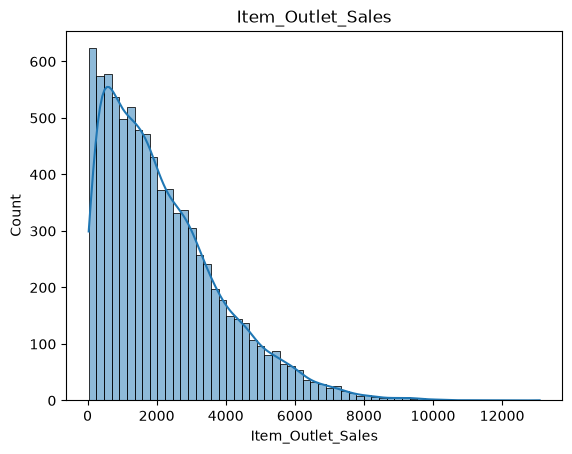

In [19]:
# 3. One column at a time

sns.histplot(df['Item_Outlet_Sales'], kde=True)
plt.title('Item_Outlet_Sales')
plt.savefig(root + '/outputs/figures/sales_histogram.png', dpi=120, bbox_inches='tight')
plt.show()

# Most sales are small and a few are very large, so the histogram is skewed to the right.

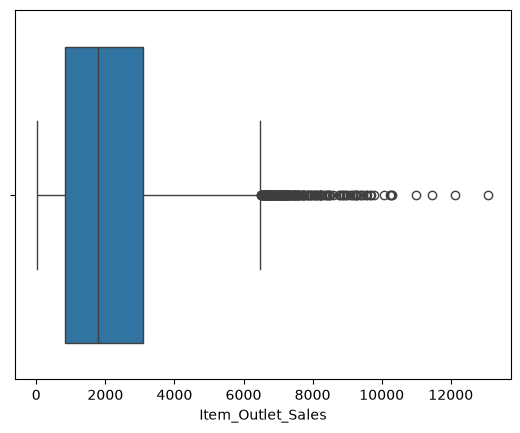

In [20]:
sns.boxplot(x=df['Item_Outlet_Sales'])
plt.show()

In [21]:
for col in ['Item_Outlet_Sales', 'Item_MRP']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print('---', col, '---')
    print('Lower Bound:', lower_bound)
    print('Upper Bound:', upper_bound)
    print('Number of outliers:', len(outliers))
    print('Percent of outliers:', len(outliers) / len(df) * 100)
    print()

# Sales has 186 outliers (2.18% of rows), all on the high side. They are real big sales, not
# mistakes, so we keep them (removing them would make the model worse on exactly the rows
# that cost the most RMSE). MRP has none.

--- Item_Outlet_Sales ---
Lower Bound: -2566.3261
Upper Bound: 6501.8699
Number of outliers: 186
Percent of outliers: 2.1823301654347063

--- Item_MRP ---
Lower Bound: -43.8993
Upper Bound: 323.3695
Number of outliers: 0
Percent of outliers: 0.0



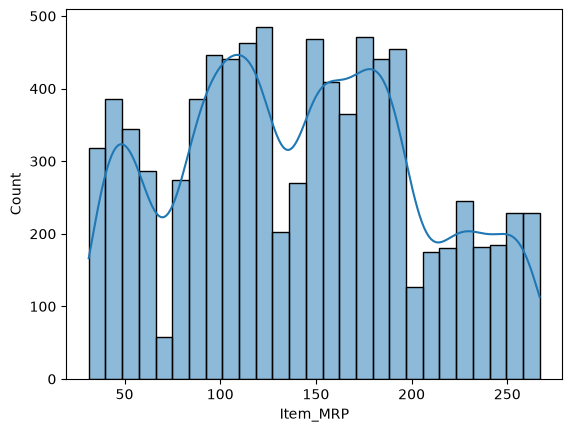

In [22]:
sns.histplot(df['Item_MRP'], kde=True)
plt.show()

In [23]:
df['Outlet_Type'].value_counts()

Outlet_Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

In [24]:
pct = df['Outlet_Type'].value_counts(normalize=True) * 100
print('Biggest outlet type:', pct.index[0], '=', round(pct.iloc[0], 2), '% of rows')
pct

Biggest outlet type: Supermarket Type1 = 65.43 % of rows


Outlet_Type
Supermarket Type1    65.434706
Grocery Store        12.706793
Supermarket Type3    10.970316
Supermarket Type2    10.888185
Name: proportion, dtype: float64

In [25]:
for col in ['Outlet_Identifier', 'Outlet_Location_Type', 'Item_Type']:
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100)
    print()

Outlet_Identifier
OUT027    935
OUT013    932
OUT049    930
OUT046    930
OUT035    930
OUT045    929
OUT018    928
OUT017    926
OUT010    555
OUT019    528
Name: count, dtype: int64
Outlet_Identifier
OUT027    10.970316
OUT013    10.935117
OUT049    10.911651
OUT046    10.911651
OUT035    10.911651
OUT045    10.899918
OUT018    10.888185
OUT017    10.864719
OUT010     6.511792
OUT019     6.195002
Name: proportion, dtype: float64

Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64
Outlet_Location_Type
Tier 3    39.305409
Tier 2    32.676288
Tier 1    28.018303
Name: proportion, dtype: float64

Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks      

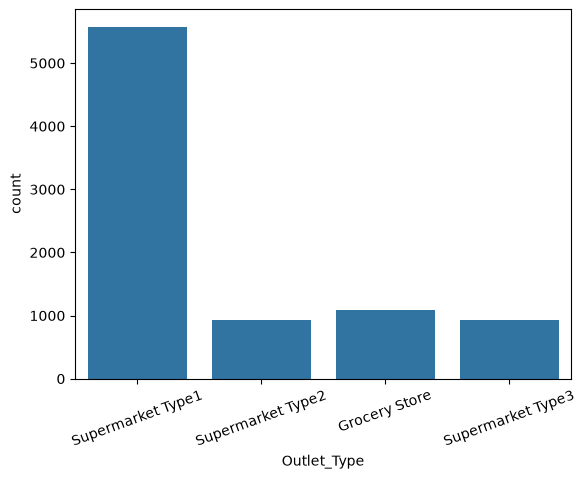

In [26]:
sns.countplot(x='Outlet_Type', data=df)
plt.xticks(rotation=20)
plt.show()

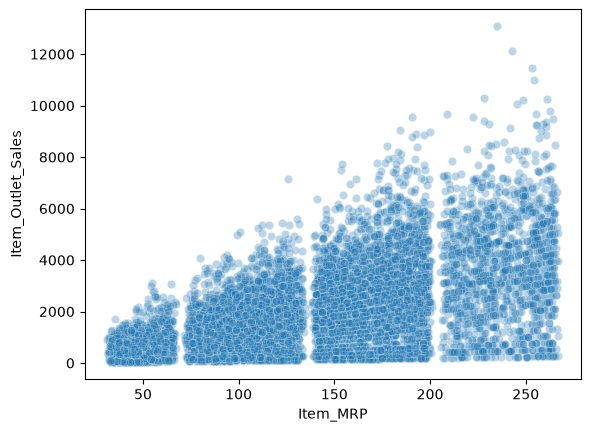

In [27]:
# 4. Sales against other columns

sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=df, alpha=0.3)
plt.savefig(root + '/outputs/figures/sales_vs_mrp.png', dpi=120, bbox_inches='tight')
plt.show()

# Dearer items sell for more money. The points fan out as the price grows.

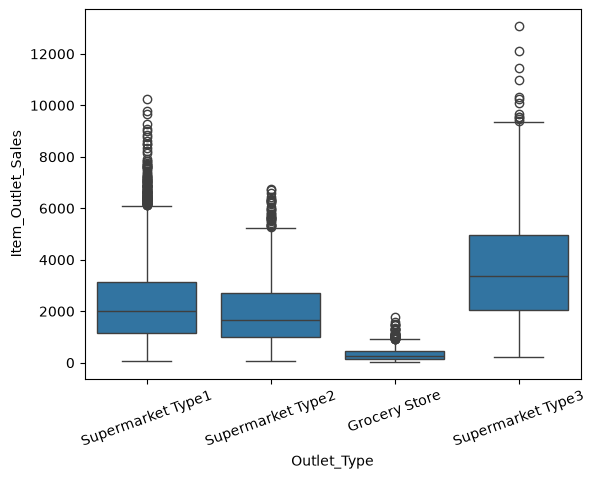

In [28]:
sns.boxplot(x='Outlet_Type', y='Item_Outlet_Sales', data=df)
plt.xticks(rotation=20)
plt.savefig(root + '/outputs/figures/sales_by_outlet_type.png', dpi=120, bbox_inches='tight')
plt.show()

In [29]:
avg = df.groupby('Outlet_Type')['Item_Outlet_Sales'].mean()
print('Type1 sells', round(avg['Supermarket Type1'] / avg['Grocery Store'], 1), 'times more than a Grocery Store on average')
avg

# Grocery stores sell far less than supermarkets, and Supermarket Type3 sells the most.

Type1 sells 6.8 times more than a Grocery Store on average


Outlet_Type
Grocery Store         339.828500
Supermarket Type1    2316.181148
Supermarket Type2    1995.498739
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64

In [30]:
df.groupby('Outlet_Identifier')['Item_Outlet_Sales'].mean()

Outlet_Identifier
OUT010     339.351662
OUT013    2298.995256
OUT017    2340.675263
OUT018    1995.498739
OUT019     340.329723
OUT027    3694.038558
OUT035    2438.841866
OUT045    2192.384798
OUT046    2277.844267
OUT049    2348.354635
Name: Item_Outlet_Sales, dtype: float64

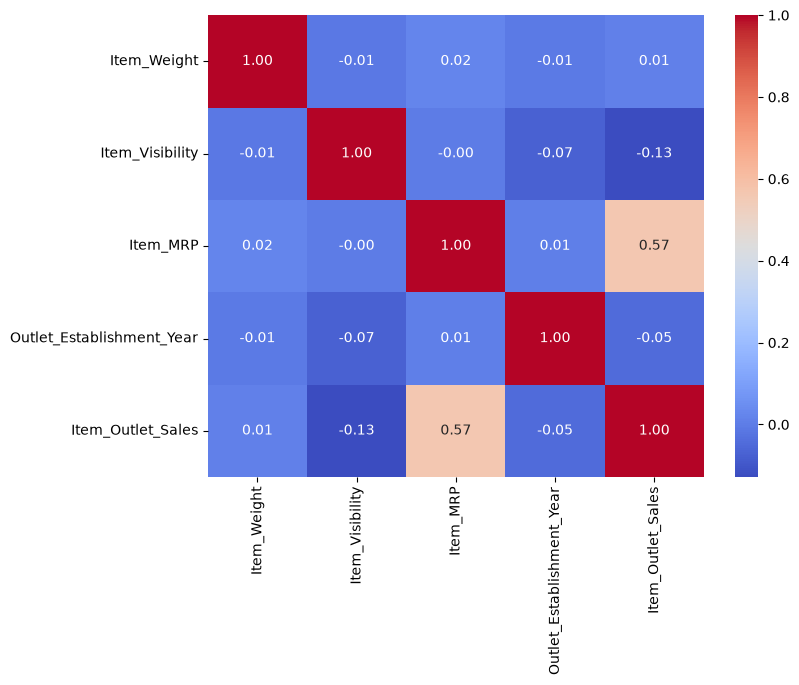

In [31]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# The only column with a clear link to sales is Item_MRP.

In [32]:
# 5. Pearson correlation
#
# Pearson's r measures how straight-line the link between two numbers is. It goes from -1 to
# +1, and 0 means no linear link.
#
# - H0: there is no linear relationship between the two columns.
# - H1: there is a linear relationship.
# - If the p-value is below 0.05 we reject H0.

for col in ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Outlet_Establishment_Year']:
    r, p = stats.pearsonr(df[col], df['Item_Outlet_Sales'])
    print(f"{col:28s} r = {r:6.3f}   p-value = {p:.4f}", '-> reject H0 (linked)' if p < 0.05 else '-> cannot reject H0 (no evidence of a link)')

# - Item_MRP: r is about 0.57 with a tiny p-value, so there is a clear positive link. This
#     is the column to build the model on.
# - Item_Visibility has a small negative r. The average visibility is 0.105 in grocery
#     stores against about 0.06 in supermarkets, and grocery stores sell less, so this link
#     mostly comes from the store type.
# - Item_Weight has r close to 0 and a large p-value (0.29), so we cannot say it is linked
#     to sales.
# - Outlet_Establishment_Year has a tiny p-value but r is only -0.05. The link is real but
#     far too weak to help.

Item_MRP                     r =  0.568   p-value = 0.0000 -> reject H0 (linked)
Item_Weight                  r =  0.012   p-value = 0.2863 -> cannot reject H0 (no evidence of a link)
Item_Visibility              r = -0.129   p-value = 0.0000 -> reject H0 (linked)
Outlet_Establishment_Year    r = -0.049   p-value = 0.0000 -> reject H0 (linked)


In [33]:
# 6. A basic test: do grocery stores really sell less?
#
# We compare the average sales of grocery stores with Supermarket Type1 using a two-sample
# t-test.
#
# - H0: both store types have the same average sales.
# - H1: the averages are different.

grocery = df[df['Outlet_Type'] == 'Grocery Store']['Item_Outlet_Sales']
super1 = df[df['Outlet_Type'] == 'Supermarket Type1']['Item_Outlet_Sales']

print('Grocery mean:', grocery.mean())
print('Supermarket Type1 mean:', super1.mean())

t, p = stats.ttest_ind(grocery, super1)
print('t =', t, ' p-value =', p)
print('Reject H0: grocery stores really sell less' if p < 0.05 else 'Cannot reject H0')

# The p-value is far below 0.05, so we reject H0: grocery stores really do sell less. So the
# model must treat every outlet separately.

Grocery mean: 339.8285004616805
Supermarket Type1 mean: 2316.181148108302
t = -42.777859363653086  p-value = 0.0
Reject H0: grocery stores really sell less


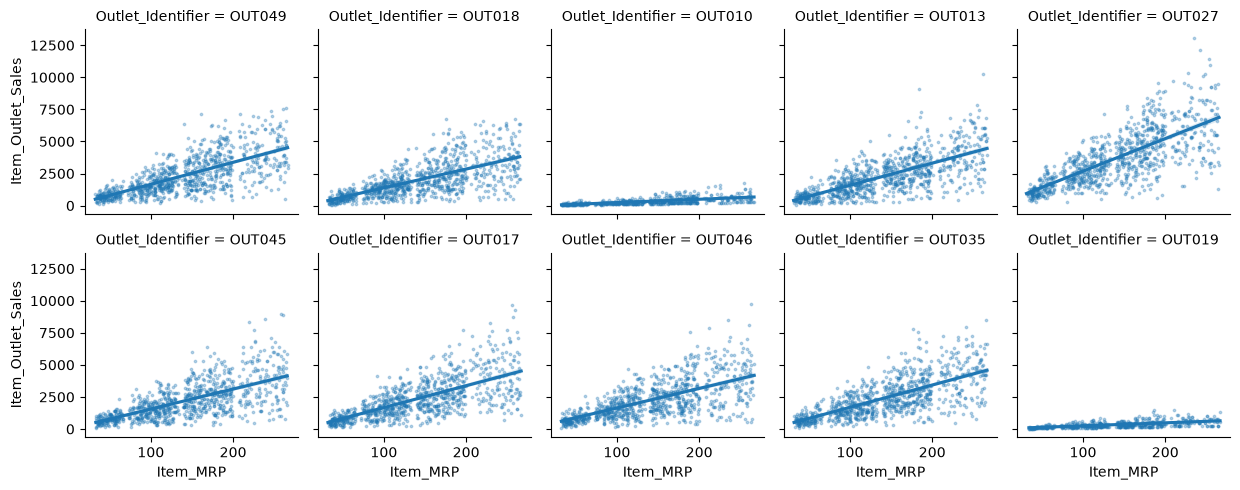

In [34]:
# 7. One line per outlet
#
# Inside one outlet, sales rise in a straight line with Item_MRP. The picture below shows
# one line per outlet.

sns.lmplot(x='Item_MRP', y='Item_Outlet_Sales', col='Outlet_Identifier', col_wrap=5, data=df,
           scatter_kws={'s': 3, 'alpha': 0.3}, height=2.5)
plt.savefig(root + '/outputs/figures/line_per_outlet.png', dpi=120, bbox_inches='tight')
plt.show()

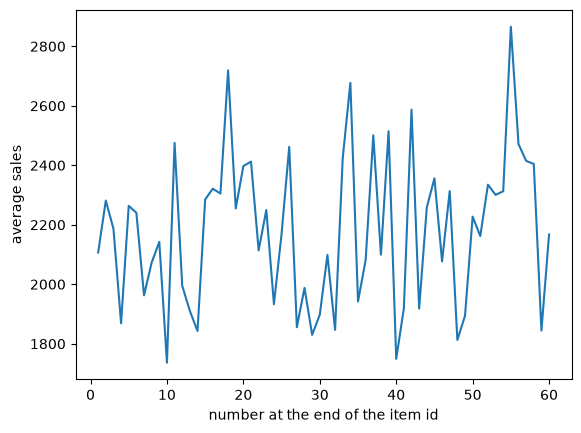

In [35]:
# The id of every item ends in a number (FDA15 has 15). The average sales for each number is
# not flat, so the number carries a little information.

df['id_num'] = df['Item_Identifier'].str[3:].astype(int)
df.groupby('id_num')['Item_Outlet_Sales'].mean().plot()
plt.xlabel('number at the end of the item id')
plt.ylabel('average sales')
plt.savefig(root + '/outputs/figures/sales_by_id_number.png', dpi=120, bbox_inches='tight')
plt.show()

In [36]:
# 8. A quick model
#
# We split the data into 80% to learn from and 20% to check, and compare two models by RMSE:
#
# 1. the same prediction (the average sales) for every row,
# 2. one straight line of sales on Item_MRP per outlet.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

tr, va = train_test_split(df, test_size=0.2, random_state=42)

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

# model 1: the average for everyone
print('Average only:', rmse(va['Item_Outlet_Sales'], tr['Item_Outlet_Sales'].mean()))

# model 2: one line per outlet
va = va.copy()
va['pred'] = 0.0
for outlet in tr['Outlet_Identifier'].unique():
    a = tr[tr['Outlet_Identifier'] == outlet]
    b = va['Outlet_Identifier'] == outlet
    line = LinearRegression().fit(a[['Item_MRP']], a['Item_Outlet_Sales'])
    va.loc[b, 'pred'] = line.predict(va.loc[b, ['Item_MRP']])

print('Line per outlet:', rmse(va['Item_Outlet_Sales'], va['pred']))
print('Error cut by', round((1 - rmse(va['Item_Outlet_Sales'], va['pred']) / rmse(va['Item_Outlet_Sales'], tr['Item_Outlet_Sales'].mean())) * 100, 1), '%')

Average only: 1651.989750472933
Line per outlet: 1014.7638762142487
Error cut by 38.6 %


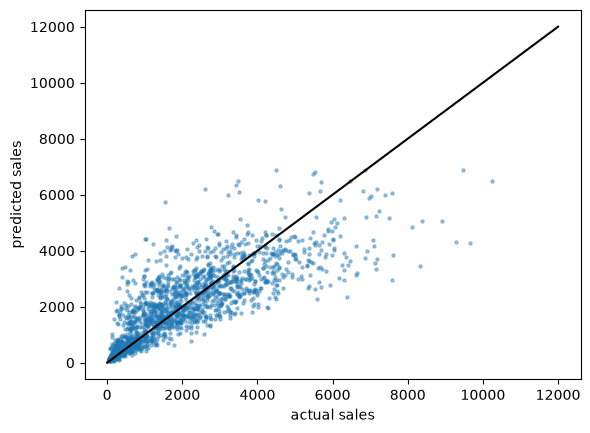

In [37]:
plt.scatter(va['Item_Outlet_Sales'], va['pred'], s=5, alpha=0.4)
plt.plot([0, 12000], [0, 12000], color='black')
plt.xlabel('actual sales')
plt.ylabel('predicted sales')
plt.savefig(root + '/outputs/figures/actual_vs_predicted.png', dpi=120, bbox_inches='tight')
plt.show()

# The points follow the black line but spread out for big sales, which is why the RMSE stays
# large (about 1000 here, against 1650 for the plain average). Much of the sales is simply
# random.
#
# The final solution (solutions/solution_v5.py) goes further: it uses a cleaner price and
# the id number, as the next sections show.

In [38]:
# 9. A hidden pattern: sales are whole units times a price
#
# The scatter of sales against Item_MRP fans out a lot. Maybe that is not pure randomness. A
# sale is money, and money comes from selling a whole number of units at a price. If every
# sale is units × price, then every sales value should be a whole multiple of some small
# step.
#
# The step that works is 0.6658. Dividing sales by it should give whole numbers.

STEP = 0.6658
df['steps'] = df['Item_Outlet_Sales'] / STEP

# how far is each value from a whole number?
gap = (df['steps'] - df['steps'].round()).abs()
print('largest gap from a whole number:', gap.max())
print('rows within 0.01 of a whole number:', (gap < 0.01).mean())

# Every one of the 8523 sales is a whole multiple of 0.6658. This is not a coincidence, so
# sales really are units × price.
#
# Now look at one item sold in 8 outlets. Its Item_MRP changes from row to row, but its
# sales do not move freely: they are 5610, 8976, 9724 ... steps.

largest gap from a whole number: 3.637978807091713e-12
rows within 0.01 of a whole number: 1.0


In [39]:
df[df['Item_Identifier'] == 'FDA15'][['Outlet_Identifier', 'Item_MRP', 'Item_Outlet_Sales', 'steps']]

,Outlet_Identifier,Item_MRP,Item_Outlet_Sales,steps
0,OUT049,249.8092,3735.1380,5610.0
831,OUT045,250.2092,5976.2208,8976.0
2599,OUT035,248.5092,6474.2392,9724.0
2643,OUT018,249.6092,5976.2208,8976.0
4874,OUT010,248.9092,498.0184,748.0
5413,OUT013,250.6092,6474.2392,9724.0
6696,OUT027,249.5092,6474.2392,9724.0
7543,OUT017,248.8092,5976.2208,8976.0


In [40]:
# The MRP of FDA15 wanders between 248.5 and 250.6, but an item has only one real price. So
# Item_MRP looks like the real price plus a small random error. We can find the real price:
# it must be a price on the 0.6658 grid, within 2 of every MRP of the item, and it must
# divide every one of the item's sales steps exactly.
#
# We recover prices from the learning part only (tr, the 80% from section 8), then check
# them.

def item_prices(d, noise=2.0):
    prices = {}
    for item, g in d.groupby('Item_Identifier'):
        k = np.round(g['Item_Outlet_Sales'] / STEP).astype(int).to_numpy()
        lo = max(int(np.ceil((g['Item_MRP'].max() - noise) / STEP)), 1)
        hi = int(np.floor((g['Item_MRP'].min() + noise) / STEP))
        fits = [q for q in range(lo, hi + 1) if np.all(k % q == 0)]
        if fits:   # if several fit, take the one nearest the average MRP
            prices[item] = min(fits, key=lambda q: abs(q * STEP - g['Item_MRP'].mean())) * STEP
    return prices

prices = item_prices(tr)
print('items with a recovered price:', len(prices), 'of', tr['Item_Identifier'].nunique())
print('validation rows whose item has a price:', va['Item_Identifier'].isin(prices).mean())

error = tr['Item_MRP'] - tr['Item_Identifier'].map(prices)
print(error.describe())

# The error MRP - real price runs from -2 to +2 with a mean of 0, like random noise. So
# Item_MRP is a noisy copy of a hidden price, and about 96% of the validation rows belong to
# an item whose price we recovered.
#
# Does the cleaner price help the line from section 8? We repeat the same line per outlet,
# once with Item_MRP and once with the recovered price.

items with a recovered price: 1479 of 1555
validation rows whose item has a price: 0.9577712609970674
count    6.447000e+03
mean     2.745463e-03
std      1.186454e+00
min     -2.000000e+00
25%     -1.000000e+00
50%      7.105427e-15
75%      1.100000e+00
max      2.000000e+00
dtype: float64


In [41]:
def line_per_outlet(price_of):
    pred = pd.Series(0.0, index=va.index)
    for outlet in tr['Outlet_Identifier'].unique():
        a = tr[tr['Outlet_Identifier'] == outlet]
        b = va['Outlet_Identifier'] == outlet
        line = LinearRegression().fit(price_of(a).to_frame('price'), a['Item_Outlet_Sales'])
        pred[b] = line.predict(price_of(va[b]).to_frame('price'))
    return rmse(va['Item_Outlet_Sales'], pred)

real_price = lambda d: d['Item_Identifier'].map(prices).fillna(d['Item_MRP'])

print('with Item_MRP:   ', line_per_outlet(lambda d: d['Item_MRP']))
print('with real price: ', line_per_outlet(real_price))
print('RMSE change from using the real price:', round(line_per_outlet(real_price) - line_per_outlet(lambda d: d['Item_MRP']), 2))

# The two numbers are almost the same. A straight line cannot use the pattern: the noise in
# MRP is at most 2 on a price of about 140, which is small next to the huge spread in how
# many units are sold.
#
# What the pattern does tell us is that sales = units × price, where the units are a whole-
# number count. So the better thing to model is the number of units (sales / price), which
# is count-like data. This is why solutions/solution_v5.py replaces Item_MRP with the
# recovered price, fits the units with a Poisson model, and multiplies back by the price.
#
# Be honest about the size of the gain: on this split the cleaner price changes nothing, and
# one fold's RMSE wobbles by about 29. The pattern is exact and worth knowing, but most of
# the remaining error is genuinely random units sold, which no price can explain.

with Item_MRP:    1014.7638762142487
with real price:  1015.1394184390234
RMSE change from using the real price: 0.38
